# 04 · Evidence traceability, freshness and the score-independent release gate (E4)
**Supports:** RQ1, RQ4, O3. Builds the traceability units for the DEMO product from the 46-row obligation catalogue, then injects lifecycle events (dependency bump, new exploited CVE, evidence tampering) and shows what the metrics and the gate do. **Synthetic product.**

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from crasme import plotting; plotting.use()
pd.set_option('display.precision', 3); pd.set_option('display.width', 140)
from crasme import traceability as t
import json, copy

In [2]:
cat = pd.DataFrame(t.load_catalogue())
print(len(cat), 'obligations'); cat.groupby(['gate', 'mandatory']).size().unstack(fill_value=0)

46 obligations


mandatory,N,Y,conditional
gate,,,
event-driven,1,6,0
lifecycle,0,14,1
pre-market,0,24,0


## 1 · A plausible mid-implementation state
Randomly (seeded) assign status to obligations to mimic an SME at week 8 of the playbook.

In [3]:
rng = np.random.default_rng(3)
units = []
for _, row in cat.iterrows():
    applicable = not (row.req_id in ('OSS-01', 'P1-m', 'REP-04'))
    st = rng.choice(['verified', 'implemented', 'in_progress', 'not_started'], p=[.45, .2, .2, .15]) if applicable else 'not_applicable'
    done = st == 'verified'
    units.append(t.TraceUnit('DEMO-001', 'build-41', row.req_id, applicable,
        'Applies to connected gateway' if applicable else ('Not an open-source steward' if row.req_id=='OSS-01' else ''),
        st, control_id=f'C-{row.req_id}' if st != 'not_started' else '', test_id=f'T-{row.req_id}' if done else '',
        evidence_uri=f'evidence/{row.req_id}.json' if done else '', evidence_sha256=('ab'*32) if done else '',
        evidence_generated_at=f'2026-10-{rng.integers(1,15):02d}T09:00:00Z' if done else '',
        owner='team' if st != 'not_started' else '', reviewer='sec-lead' if done or not applicable else '',
        reviewed_at='2026-10-15T10:00:00Z' if done else ''))
errs = t.validate_units([u.to_dict() for u in units]); print('schema errors:', errs[:3])
cov = t.coverage(units, set(cat.req_id)); {k: cov[k] for k in ('obligations','applicable','complete','coverage','unjustified_not_applicable')}

schema errors: ["[21, 'applicability_justification']: '' is too short", "[38, 'applicability_justification']: '' is too short"]


{'obligations': 46,
 'applicable': 43,
 'complete': 20,
 'coverage': 0.46511627906976744,
 'unjustified_not_applicable': ['P1-m', 'REP-04']}

The schema rejects a *not applicable* decision without justification (P1-m, REP-04 above) — this is the intended behaviour: an N/A without rationale is a finding.

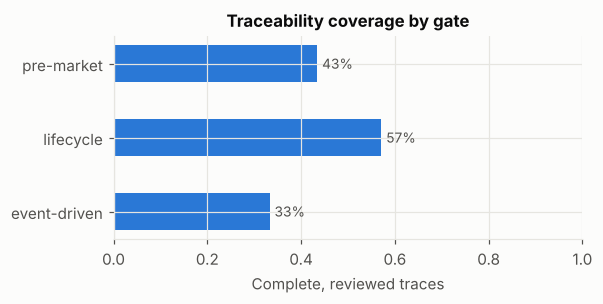

In [4]:
by_gate = (pd.DataFrame([{**u.to_dict(), 'gate': g} for u, g in zip(units, cat.gate)])
           .assign(complete=[u.is_complete() for u in units]).query('applicable')
           .groupby('gate').complete.mean())
fig, ax = plt.subplots(figsize=(5.5, 2.4))
ax.barh(by_gate.index, by_gate.values, color=plotting.SERIES[0], height=0.5)
for i, v in enumerate(by_gate.values): ax.text(v + 0.01, i, f'{v:.0%}', va='center', fontsize=9, color=plotting.INK2)
ax.set_xlim(0, 1); ax.set_xlabel('Complete, reviewed traces'); ax.set_title('Traceability coverage by gate'); plt.show()

## 2 · Lifecycle events

In [5]:
# Event 1: dependency bump on 2026-10-16 -> evidence generated before it is stale
affected = {'P2-1', 'P2-2', 'P2-3', 'SC-01', 'P1-a'}   # evidence a dependency bump invalidates
fr = t.freshness(units, '2026-10-16T00:00:00Z', affected); print('stale among affected:', fr['stale'], '| stale share:', round(fr['stale_share'], 2), '| median lag days:', round(fr['median_lag_days'], 1))
# Event 2: release gate for build-42 with an exploited CVE open
mandatory = set(cat.query("mandatory == 'Y' and gate == 'pre-market'").req_id)
gate = t.release_gate(units, mandatory, [{'id': 'CVE-2021-44906', 'known_exploited': True}], 'build-42')
print('release allowed:', gate['release_allowed'], '| blockers:', len(gate['blockers'])); gate['blockers'][:6]

stale among affected: ['P1-a', 'P2-2', 'SC-01'] | stale share: 1.0 | median lag days: 8.6
release allowed: False | blockers: 24


['CA-01: applicable but evidence incomplete/unreviewed',
 'DOC-EU-01: evidence is for build build-41, not build-42',
 'ID-01: applicable but evidence incomplete/unreviewed',
 'OP-01: applicable but evidence incomplete/unreviewed',
 'P1-01: applicable but evidence incomplete/unreviewed',
 'P1-a: evidence is for build build-41, not build-42']

In [6]:
# Event 3: evidence tampering is detected by hash verification
import tempfile, pathlib as pl
tmp = pl.Path(tempfile.mkdtemp()); (tmp/'evidence').mkdir()
f = tmp/'evidence'/'P2-1.json'; f.write_text('{"sbom": "v1"}')
u = copy.deepcopy(units[0]); u.requirement_id='P2-1'; u.evidence_uri='evidence/P2-1.json'; u.evidence_sha256=t.sha256_file(f)
print('before:', t.verify_hashes([u], tmp)); f.write_text('{"sbom": "edited"}'); print('after edit:', t.verify_hashes([u], tmp))

before: {'P2-1': True}
after edit: {'P2-1': False}


## 3 · E4 experiment design (to run on pilot repositories)
Inject scripted change events into a forked pilot repo (dependency bump, new CVE published against a component, config change, support-period change) and measure **detection latency** (event → evidence marked stale), **re-evidencing effort** and **gate decisions** with and without the CRA-SME pipeline. Metrics map 1:1 to concept note §8 (*evidence freshness*, *requirements traceability*, *false assurance*).